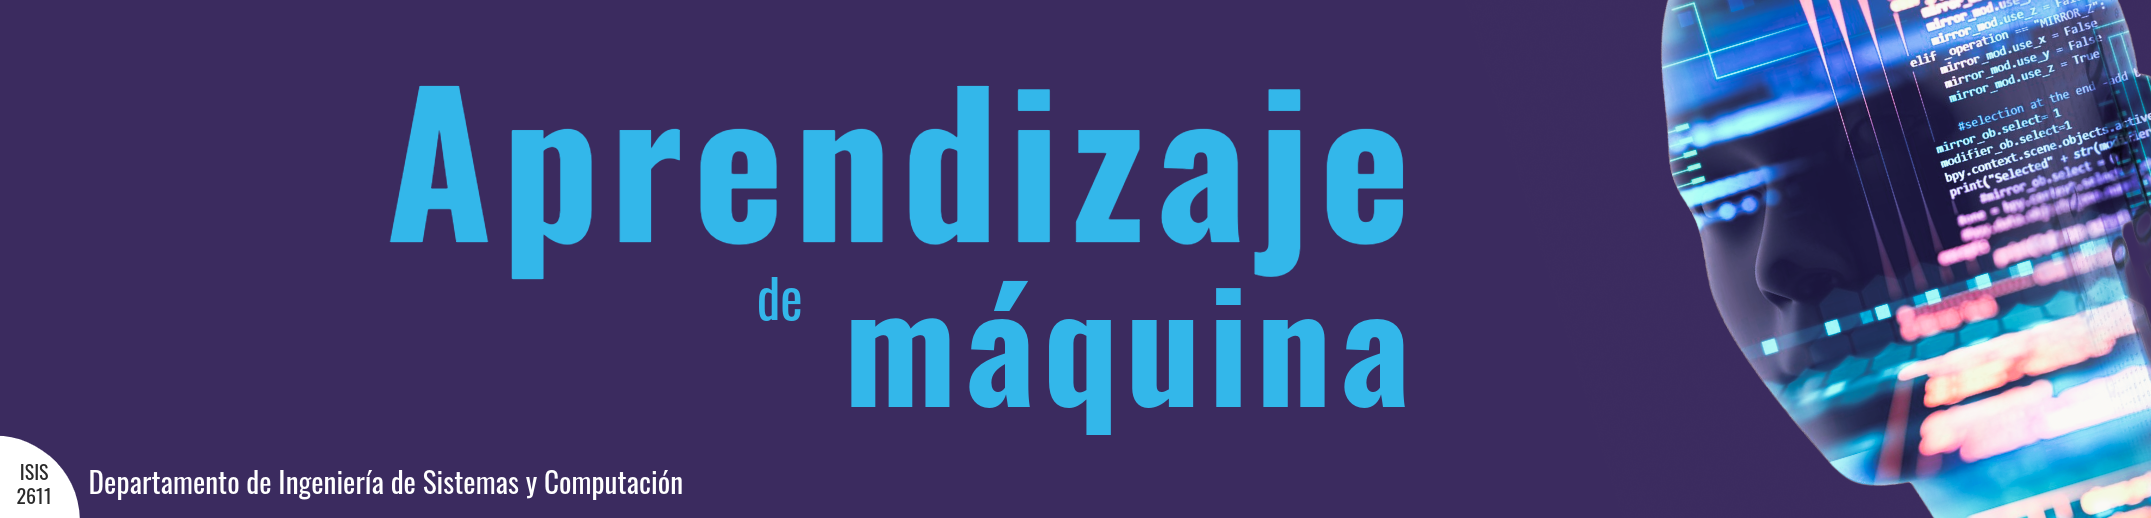

# Árboles de Decisión

En esta práctica exploraremos el uso de los Árboles de Decisión en tareas de clasificación. Estos modelos se distinguen por ser clasificadores multiclase nativos, capaces de gestionar múltiples categorías de forma directa. Su arquitectura se basa en la partición recursiva del espacio de características mediante nodos de decisión, los cuales evalúan condiciones sobre las variables del conjunto de datos. Al aplicar sucesivamente estas reglas simples, el modelo logra descomponer problemas de alta dimensionalidad en una estructura jerárquica, permitiendo aproximar fronteras de decisión no lineales con un nivel de interpretabilidad superior a otros modelos de caja negra.

Se utilizará el [Smart Mobility traffic Dataset](https://www.kaggle.com/datasets/ziya07/smart-mobility-traffic-dataset?select=smart_mobility_dataset.csv), un conjunto de datos orientado al análisis y optimización de la movilidad en entornos de ciudades inteligentes. Este conjunto integra distintos tipos de variables, como estadísticas de tráfico, reportes de accidentes, condiciones climáticas y niveles de emisiones vehiculares, con el objetivo de predecir el nivel de congestión del tráfico.

Se seguirá una estructura similar a la de las anteriores prácticas: exploración, limpieza y preparación de datos, construcción de un pipeline, búsqueda de hiperparámetros y evaluación. A diferencia de esas prácticas, aquí el modelo tiene una estructura completamente distinta (no lineal), así que dedicaremos una sección breve a entender cómo construye sus preguntas y cómo mide qué tan buena es cada una.

Este material está dividido en las siguientes partes:

1. Importación de librerías
2. ¿Qué es un árbol de decisión?
3. Carga de los datos
4. Exploración del conjunto de datos
5. Partición de los datos
6. Esquema de partición de registros y criterios de impureza
7. Construcción del pipeline de procesamiento y modelado
8. Entrenamiento del árbol de decisión con búsqueda de hiperparámetros
9. Evaluación del mejor modelo
10. Interpretabilidad del modelo
11. Persistencia del pipeline entrenado
12. Ejercicios


## 1. Importación de librerías


In [1]:
import os
import joblib
import pandas as pd
import numpy as np
import seaborn as sns

from matplotlib import pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

## 2. ¿Qué es un árbol de decisión?

Hasta ahora hemos trabajado con modelos que combinan todas las variables en una sola fórmula (regresión lineal, Ridge, Lasso, regresión logística). Un **árbol de decisión** funciona distinto: en vez de una fórmula, construye una **secuencia de preguntas simples** sobre las variables, organizadas en forma de árbol. Cada pregunta es un **nodo interno**, cada respuesta lleva a una rama, y al final de cada camino hay una **hoja** que asigna una clase.

```
        ¿Traffic_Speed_kmh < 20?
           /            \
          Sí             No
          |         ¿Road_Occupancy_% > 80?
      Congestión         /        \
        Alta            Sí         No
                    Congestión   Congestión
                      Alta        Media/Baja
```

A diferencia de un modelo lineal (donde todas las variables con coeficiente distinto de cero participan en cada predicción), en un árbol cada instancia solo "toca" las preguntas que están en su propio camino desde la raíz hasta su hoja — el modelo puede ignorar variables irrelevantes para un caso particular sin que eso implique un paso extra de selección de variables. Construir el árbol consiste en encontrar, en cada nodo, la pregunta que separa mejor las clases — eso es justamente lo que veremos en la sección 6.


## 3. Carga de los datos


In [2]:
datos_movility = pd.read_csv(os.path.join('.', 'data', 'smart_mobility_dataset.csv'))

In [3]:
data = datos_movility.copy()

El diccionario de los datos es el siguiente:

| Variable               | Tipo       | Descripción                                                      | Unidad / Escala     |
|:-----------------------|:-----------|:-----------------------------------------------------------------|:--------------------|
| Timestamp              | Temporal   | Marca temporal del registro del sistema de monitoreo de tráfico.| Fecha-hora          |
| Latitude               | Numérica   | Latitud geográfica del punto donde se registró la medición.     | Grados decimales    |
| Longitude              | Numérica   | Longitud geográfica del punto donde se registró la medición.    | Grados decimales    |
| Vehicle_Count          | Numérica   | Número de vehículos detectados por sensores.                    | Conteo de vehículos |
| Traffic_Speed_kmh      | Numérica   | Velocidad promedio del tráfico.                                 | km/h                |
| Road_Occupancy_%       | Numérica   | Porcentaje de ocupación de la vía (0–100).                      | %                   |
| Traffic_Light_State    | Categórica | Estado del semáforo cercano (Red, Yellow, Green).               | Estado semáforo     |
| Weather_Condition      | Categórica | Condiciones meteorológicas (Clear, Rain, Fog, Snow).            | Condición climática |
| Accident_Report        | Binaria    | Indica si se reportó un accidente (1 = Sí, 0 = No).             | Indicador           |
| Sentiment_Score        | Numérica   | Puntaje de sentimiento sobre el tráfico (-1, 1).                | Escala sentimiento  |
| Ride_Sharing_Demand    | Numérica   | Solicitudes de transporte compartido.                           | Conteo solicitudes  |
| Parking_Availability   | Numérica   | Espacios de estacionamiento disponibles.                        | Espacios            |
| Emission_Levels_g_km   | Numérica   | Nivel estimado de emisiones vehiculares.                        | g/km                |
| Energy_Consumption_L_h | Numérica   | Consumo energético estimado.                                    | L/h                 |
| Traffic_Condition      | Categórica | Clasificación del nivel de tráfico (Low, Medium, High).         | Nivel congestión    |

## 4. Exploración del conjunto de datos


In [4]:
data.shape

(5000, 15)

Se identifica que el dataset está compuesto por 5000 registros, con 15 variables que lo describen.

In [5]:
data.head()

,Timestamp,Latitude,Longitude,Vehicle_Count,Traffic_Speed_kmh,Road_Occupancy_%,Traffic_Light_State,Weather_Condition,Accident_Report,Sentiment_Score,Ride_Sharing_Demand,Parking_Availability,Emission_Levels_g_km,Energy_Consumption_L_h,Traffic_Condition
0,2024-03-01 00:00:00,40.842275,-73.703149,205,49.893435,82.652780,Yellow,Clear,0,-0.609199,2,45,450.760055,19.574337,High
1,2024-03-01 00:05:00,40.831119,-73.987354,202,22.383965,45.829298,Green,Clear,0,0.965442,16,1,321.800341,5.385554,High
2,2024-03-01 00:10:00,40.819549,-73.732462,252,46.889699,82.772465,Green,Rain,0,0.289660,16,49,231.152655,10.277477,High
3,2024-03-01 00:15:00,40.725849,-73.980134,37,5.730536,37.695567,Red,Fog,0,-0.271965,66,10,410.384292,29.243279,High
4,2024-03-01 00:20:00,40.813265,-73.961631,64,61.348034,22.313358,Red,Snow,0,-0.797606,3,5,364.466342,16.801459,Low


#### Verificación de Consistencia y Validez

In [6]:
data.describe()

,Latitude,Longitude,Vehicle_Count,Traffic_Speed_kmh,Road_Occupancy_%,Accident_Report,Sentiment_Score,Ride_Sharing_Demand,Parking_Availability,Emission_Levels_g_km,Energy_Consumption_L_h
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,40.749645,-73.847433,153.921200,42.111096,54.748397,0.096000,-0.005652,50.487800,24.613000,272.174927,17.343243
std,0.086123,0.086204,83.523342,21.707720,26.145238,0.294621,0.583790,28.484426,14.532511,130.086372,7.208277
min,40.600016,-73.999987,10.000000,5.002789,10.005031,0.000000,-0.999819,1.000000,0.000000,50.136855,5.003787
25%,40.675403,-73.920281,80.000000,23.195752,32.089653,0.000000,-0.500154,26.000000,12.000000,160.564433,11.098761
50%,40.748875,-73.846058,156.000000,42.191599,54.657297,0.000000,-0.010564,50.000000,24.000000,272.045513,17.153791
75%,40.824735,-73.771685,226.000000,60.751760,77.581720,0.000000,0.500518,75.000000,37.000000,382.242055,23.516595
max,40.899972,-73.700159,299.000000,79.997556,99.999729,1.000000,0.999354,99.000000,49.000000,499.922663,29.995416


In [7]:
data['Traffic_Light_State'].value_counts()

Traffic_Light_State
Yellow    1726
Green     1651
Red       1623
Name: count, dtype: int64

In [8]:
data['Weather_Condition'].value_counts()

Weather_Condition
Rain     1279
Snow     1257
Fog      1245
Clear    1219
Name: count, dtype: int64

#### Verificación de Completitud

In [9]:
data.isnull().sum()/len(data) * 100

Timestamp                 0.0
Latitude                  0.0
Longitude                 0.0
Vehicle_Count             0.0
Traffic_Speed_kmh         0.0
Road_Occupancy_%          0.0
Traffic_Light_State       0.0
Weather_Condition         0.0
Accident_Report           0.0
Sentiment_Score           0.0
Ride_Sharing_Demand       0.0
Parking_Availability      0.0
Emission_Levels_g_km      0.0
Energy_Consumption_L_h    0.0
Traffic_Condition         0.0
dtype: float64

#### Verificación de Unicidad

In [10]:
duplicate_percentage = data.iloc[:, 1:].duplicated().sum()/len(data) * 100
print(f'Porcentaje de registros duplicados (sin contar el timestamp): {duplicate_percentage:.3f}%')

Porcentaje de registros duplicados (sin contar el timestamp): 0.000%



Nuestra variable objetivo es `Traffic_Condition`. Podemos mostrar y visualizar en qué proporción se persentan las clases:


In [11]:
data['Traffic_Condition'].value_counts().to_frame('conteo')\
    .assign(porcentaje=lambda x: (x['conteo']/x['conteo'].sum()*100).round(2))

,conteo,porcentaje
Traffic_Condition,,
High,3166,63.32
Medium,1475,29.50
Low,359,7.18


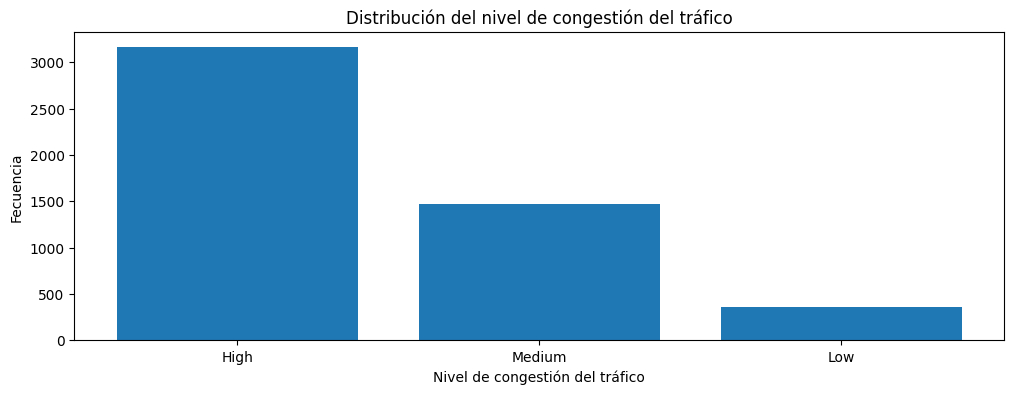

In [12]:
# Tamaño de la gráfica
plt.figure(figsize=(12,4))

# Cantidad de apariciones de cada año de construcción
plot_data = data['Traffic_Condition'].value_counts()

# Valores únicos (años) y sus frecuencias
x = plot_data.index
y = plot_data.values

# Gráfico de barras
plt.bar(x,y)

# Títulos de los ejes y del gráfico
plt.xlabel("Nivel de congestión del tráfico")
plt.ylabel("Fecuencia")
plt.title('Distribución del nivel de congestión del tráfico')

# Mostrar la gráfica
plt.show()

### Análisis de calidad

La exploración realizada no evidencia problemas de completitud ni duplicados. Los rangos observados en las variables numéricas y las categorías presentes en las variables cualitativas son compatibles con lo esperado según el diccionario de datos. En esta revisión inicial tampoco se identificaron inconsistencias evidentes que requieran corrección.

Sin embargo, se identificó un desbalance en la variable objetivo `Traffic_Condition`: la categoría `High` representa aproximadamente el 63% de los registros, `Medium` cerca del 30% y `Low` solo alrededor del 7%. Este desbalance podría afectar el desempeño del modelo sobre la clase minoritaria.

Con base en estas verificaciones iniciales, no se identifican problemas de calidad que requieran una transformación adicional antes de realizar la partición de los datos.

## 5. Partición de los datos


In [13]:
x = data.drop(columns=['Traffic_Condition'])
y = data['Traffic_Condition']

In [14]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)


Para manterner la misma proporción de las clases en ambos conjuntos se utiliza la opción `stratify=y`.


## 6. Esquema de partición de registros y criterios de impureza

Para construir cada pregunta, el algoritmo prueba distintos umbrales sobre las características disponibles y elige la partición que más reduce la **impureza**, es decir, qué tan mezcladas están las clases en cada grupo resultante. Para una variable numérica, por ejemplo, puede evaluar una condición como `Traffic_Speed_kmh < 20`. En esta práctica, las variables categóricas se transformarán previamente mediante *one-hot encoding*, por lo que el árbol evaluará condiciones sobre los indicadores binarios generados para cada categoría.

Dos medidas de impureza son las más usadas:

**Entropía**: $I_H(t) = -\sum_{i=1}^{c} p(i|t)\log_2 p(i|t)$

**Índice de Gini**: $I_G(t) = 1 - \sum_{i=1}^{c} p(i|t)^2$

donde $p(i|t)$ es la proporción de datos del nodo $t$ que pertenecen a la clase $i$. Ambas valen 0 cuando el nodo es puro (una sola clase) y aumentan cuanto más mezcladas están las clases.

Para decidir qué tan buena es una pregunta específica se usa la **ganancia de información**: la impureza del nodo padre menos el promedio ponderado de la impureza de sus hijos.

$$IG(D_p, f) = I(D_p) - \frac{N_{izq}}{N_p}I(D_{izq}) - \frac{N_{der}}{N_p}I(D_{der})$$

El árbol prueba muchas preguntas posibles en cada nodo y se queda con la que maximiza $IG$. Esto es justamente lo que controla el hiperparámetro `criterion` (`gini`, `entropy`, `log_loss`) que verás más adelante en la búsqueda de hiperparámetros.

### Un ejemplo numérico rápido

Supongamos un nodo con 20 registros, con una proporción de clases similar a la que vimos en la exploración (`High` mayoritaria): 12 `High`, 6 `Medium`, 2 `Low`. Si la pregunta "¿`Accident_Report` = 1?" separa el nodo en un hijo izquierdo de 16 registros (8 `High`, 6 `Medium`, 2 `Low`) y un hijo derecho de 4 registros (los 4 `High`, nodo puro), la ganancia de información con el índice de Gini es:


In [15]:
def gini(proporciones):
    return 1 - sum(p**2 for p in proporciones)

gini_padre = gini([12/20, 6/20, 2/20])
gini_izq   = gini([8/16, 6/16, 2/16])
gini_der   = gini([4/4, 0/4, 0/4])

ganancia = gini_padre - (16/20)*gini_izq - (4/20)*gini_der

print(f"Gini nodo padre:        {gini_padre:.4f}")
print(f"Gini hijo izquierdo:    {gini_izq:.4f}")
print(f"Gini hijo derecho:      {gini_der:.4f}")
print(f"Ganancia de información: {ganancia:.4f}")

Gini nodo padre:        0.5400
Gini hijo izquierdo:    0.5938
Gini hijo derecho:      0.0000
Ganancia de información: 0.0650


El árbol repite este cálculo para **todas** las preguntas posibles sobre **todas** las variables (todos los umbrales de `Traffic_Speed_kmh`, todas las categorías de `Weather_Condition`, etc.) y elige, en cada nodo, la que produzca la mayor ganancia de información.

#### Ejercicio

Calcule a mano el índice de Gini para un hijo izquierdo distinto: 10 `High`, 4 `Medium`, 2 `Low` (16 registros). Verifique su cálculo usando la función `gini()` definida arriba.


In [16]:
# Su cálculo a mano: Gini = ...

# Verificación con código:


## 7. Construcción del pipeline

Para la construcción del pipeline se comienza por eliminar aquellas variables que no aportan información significativa para resolver el problema de clasificación. En este caso las variables de `Timestamp`, `Latitude`, y `Longitude` se pueden eliminar, ya que su inclusión podría inducir un sesgo espacio-temporal que limitaría la capacidad de generalización del modelo. El objetivo es que el clasificador aprenda a identificar estados de congestión con base en la dinámica del tráfico y factores ambientales. 

Ahora bien, aunque es posible crear una función para eliminar explícitamente las variables no deseadas, esto no es necesario cuando se utiliza `ColumnTransformer`. Por defecto, este componente solo mantiene las columnas a las que se les aplica alguna transformación (remainder='drop') y elimina automáticamente las demás. Por lo tanto, no se requiere incluir un paso adicional en el pipeline para eliminar variables que no se desean utilizar en el modelo. Entonces, solo se creeará una lista con variables a eliminar para poder depurar las variables numéricas y categóricas posteriormente. 

Vale la pena anotar que los árboles de decisión realizan una selección de variables de forma **embebida**: en cada nodo, el algoritmo elige automáticamente la variable que mejor reduce la impureza, por lo que las variables poco informativas simplemente no se usan para partir. Retomaremos esta idea en la sección de interpretabilidad, al revisar la importancia de variables que aprendió el árbol.


In [17]:
cols_to_drop = ['Timestamp', 'Latitude', 'Longitude']

Se separan las variables numéricas de las categóricas para poder aplicar las transformaciones correspondientes a cada tipo de variable.

In [18]:
categorical_features = X_train.select_dtypes(include=['object']).columns.drop(cols_to_drop, errors="ignore")
numerical_features = X_train.select_dtypes(include=['number']).columns.drop(cols_to_drop, errors="ignore")

Aunque el uso de `StandardScaler()` es habitual en algoritmos sensibles a la magnitud de las variables, no es necesario para los Árboles de Decisión. Sus particiones dependen del orden de los valores y de los umbrales que reducen la impureza, no de distancias entre observaciones ni de la magnitud relativa entre características. Por esta razón, el escalado no modifica la lógica de las particiones y se omite en esta práctica.

Para las variables categóricas sigue siendo recomendado utilizar `OneHotEncoder()`:

In [19]:
categorical_transformer = OneHotEncoder(
    handle_unknown='ignore',
    drop='if_binary'
)


Una vez con las transformaciones definidas para las variables categóricas, se utiliza `ColumnTransformer()` para aplicar estas transformaciones. No obstante, vale la pena mencionar que como las variables numéricas no requieren transformaciones, se utiliza el string `'passthrough'` para indicar que las variables numéricas no se deberian eliminar.


In [20]:
preprocessor = ColumnTransformer(
    transformers=[
        ('numerical', 'passthrough', numerical_features),
        ('categorical', categorical_transformer, categorical_features)
    ]
)


A continuación, se crea el pipeline final. Este estará compuesto del preprocesador previamente definido, y del Árbol de Decisión como modelo de clasificación.


In [21]:
decision_tree_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', DecisionTreeClassifier())
])

## 8. Entrenamiento del modelo de Árbol de Decisión con búsqueda de hiperparámetros


Los hiperparámetros de los Árboles de Decisión se dividen en dos categorías fundamentales: aquellos que definen el criterio de partición para identificar umbrales de decisión óptimos, y aquellos que regulan la topología del modelo. Parámetros como la profundidad máxima, o el máximo número de hojas, controlan la complejidad del árbol. En esta sección, se realizará una búsqueda de hiperparámetros para encontrar la configuración que maximice la capacidad de generalización del árbol.

| Hiperparámetro | Qué controla |
|---|---|
| `criterion` | Qué medida de impureza usar para elegir la mejor pregunta (`gini`, `entropy`, `log_loss`) |
| `splitter` | Si busca la mejor pregunta posible (`best`) o entre un subconjunto aleatorio (`random`) |
| `max_features` | Cuántas variables considera en cada partición |
| `max_depth` | Cuántos niveles de preguntas puede tener el árbol como máximo |
| `max_leaf_nodes` | Cuántas hojas (respuestas finales) puede tener el árbol como máximo |

> **Analogía**: entrenar un árbol sin restricciones es como dejar crecer un árbol de jardín sin podarlo — termina con tantas ramas que se vuelve difícil de leer, y varias de ellas solo reflejan una rama torcida que creció por casualidad (ruido), no una forma realmente útil. `max_depth` y `max_leaf_nodes` son las **tijeras de podar**: limitan cuánto puede crecer el árbol, obligándolo a quedarse con las ramas realmente importantes.

In [22]:
param_grid = [
    {   # Hiperparámetros del criterio de partición
        'model__criterion': ['gini', 'entropy', 'log_loss'],
        'model__splitter': ['best', 'random'],
        'model__max_features': ['sqrt', 'log2', None],

        # Hiperparámetros de complejidad del árbol
        'model__max_depth': [5, 10, 15],
        'model__max_leaf_nodes': [3, 9, 18, 27]
    }
]

Para realizar la validación cruzada se utilizará `StratifiedKFold()`. Al tratarse de un problema de clasificación con clases desbalanceadas, esta variante mantiene aproximadamente la proporción de `High`, `Medium` y `Low` en cada subconjunto. Se especifican 10 particiones mediante `n_splits` y se utiliza `shuffle=True` para reordenar los registros antes de construirlas.

In [23]:
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

Para la búsqueda de hiperparámetros se empleará `GridSearchCV()` utilizando como métrica el `F1-score`. Dado que se trata de un problema de clasificación multiclase con una distribución desbalanceada (`High` ≈ 63%, `Medium` ≈ 30%, `Low` ≈ 7%), en esta práctica se utilizará `f1_macro`.

`f1_macro` calcula el F1 de cada clase y luego promedia los resultados asignando el mismo peso a todas las categorías. De esta manera, el buen desempeño en la clase mayoritaria no oculta posibles dificultades en la clase `Low`. Como alternativa, `f1_weighted` ponderaría cada clase según su frecuencia y, por tanto, daría mayor influencia a las categorías más representadas.

In [24]:
decision_tree_grid = GridSearchCV(estimator=decision_tree_pipeline, param_grid=param_grid, cv=kfold, scoring='f1_macro', n_jobs=-1, verbose=1)

In [25]:
decision_tree_grid.fit(X_train, y_train)

Fitting 10 folds for each of 216 candidates, totalling 2160 fits


,estimator,Pipeline(step...lassifier())])
,param_grid,"[{'model__criterion': ['gini', 'entropy', ...], 'model__max_depth': [5, 10, ...], 'model__max_features': ['sqrt', 'log2', ...], 'model__max_leaf_nodes': [3, 9, ...], ...}]"
,scoring,'f1_macro'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('numerical', ...), ('categorical', ...)]"



Se exploran los resultados obtenidos de la búsqueda:


In [26]:
print('Mejores hiperparámetros:\n')
display(decision_tree_grid.best_params_)
print(f'\nMejor puntaje medio en CV: {decision_tree_grid.best_score_:.3f}')

Mejores hiperparámetros:



{'model__criterion': 'gini',
 'model__max_depth': 10,
 'model__max_features': None,
 'model__max_leaf_nodes': 9,
 'model__splitter': 'best'}


Mejor puntaje medio en CV: 1.000



Se genera un reporte del desempeño de cada combinación de hiperparámetros evaluada mediante validación cruzada.


In [27]:
results = pd.DataFrame(decision_tree_grid.cv_results_)
cols = [
    'param_model__criterion',
    'mean_test_score',
    'std_test_score',
    'rank_test_score'
]
summary = results[cols].sort_values(by='rank_test_score')
display(summary)

,param_model__criterion,mean_test_score,std_test_score,rank_test_score
188,log_loss,0.999793,0.000622,1
44,gini,0.999793,0.000622,1
46,gini,0.999793,0.000622,1
66,gini,0.999793,0.000622,1
68,gini,0.999793,0.000622,1
...,...,...,...,...
145,log_loss,0.269536,0.033098,212
9,gini,0.266061,0.022674,213
201,log_loss,0.258482,0.000286,214
169,log_loss,0.258482,0.000286,214


## 9. Evaluación del mejor modelo

Ahora se utilizará el mejor modelo encontrado durante el proceso de `GridSearch`, almacenado en best_model, para aplicar el pipeline completo al conjunto de prueba para evaluar su desempeño.

In [28]:
best_model = decision_tree_grid.best_estimator_

> **Antes de ejecutar la celda siguiente**: vas a ver un desempeño muy alto en el conjunto de prueba. Antes de asumir que el modelo es excelente, pregúntate: ¿es razonable un desempeño casi perfecto en un problema real de predicción de tráfico? Guarda esa pregunta — la retomamos justo después de ver el resultado.


In [29]:
y_pred_best = best_model.predict(X_test)
print(classification_report(y_test, y_pred_best))

              precision    recall  f1-score   support

        High       1.00      1.00      1.00       633
         Low       1.00      0.99      0.99        72
      Medium       1.00      1.00      1.00       295

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000



El reporte de evaluación sobre el conjunto de prueba muestra un desempeño prácticamente perfecto. Este resultado requiere revisar cómo fue construida la variable objetivo antes de interpretarlo como evidencia de una capacidad predictiva excepcional.

> **¿Es data leakage?** En este conjunto de datos sintético, `Traffic_Condition` puede reproducirse mediante reglas basadas en `Vehicle_Count`, `Traffic_Speed_kmh`, `Road_Occupancy_%` y `Accident_Report`. Por tanto, el árbol está aproximando la regla utilizada para construir la etiqueta. Esto no constituye necesariamente *data leakage*: habría fuga de información si durante la predicción se utilizaran datos que no estarían disponibles en el momento de uso del modelo, información futura o variables derivadas de la propia etiqueta. Tampoco corresponde llamar *proxy* a estas cuatro variables únicamente porque permiten reconstruir el objetivo.
>
> El resultado sí indica que el problema predictivo es artificialmente sencillo. En un proyecto real, un desempeño de este nivel debería motivar una revisión del diccionario de datos, del origen de la variable objetivo y del momento en que cada predictor estaría disponible.

La exactitud alcanza valores muy altos en las tres clases y solo se observa un error de clasificación para `Low`. En este contexto sintético, el resultado es coherente con la relación determinista existente entre la variable objetivo y las cuatro características señaladas.


Para entrar a detalle sobre los resultados del reporte de clasificación, se utiliza la matriz de confusión correspondiente las predicciones del conjunto de evaluación.


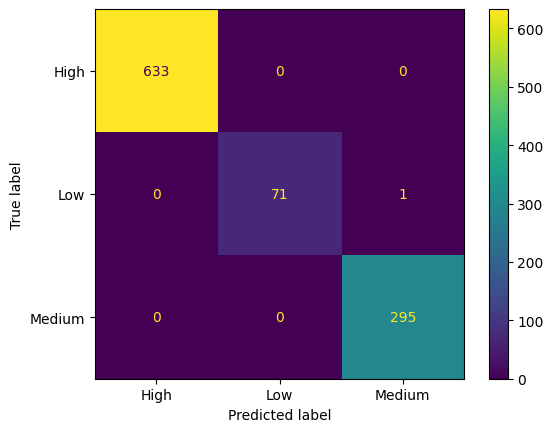

In [30]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_best)
plt.show()

La matriz de confusión muestra un único error: una observación de la clase `Low` fue clasificada como `Medium`. El desempeño es, por tanto, prácticamente perfecto en las tres clases. Sin embargo, el clasificador trata `Low`, `Medium` y `High` como etiquetas nominales; por ello, este resultado no debe interpretarse como evidencia de que el modelo haya aprendido explícitamente una estructura ordinal entre las categorías.

## 10. Interpretabilidad del modelo

Como se mencionó anteriormente, una de las principales ventajas de los árboles de decisión es su interpretabilidad, ya que permiten comprender con relativa facilidad cómo el modelo toma sus decisiones. Por esta razón, a continuación se analizará el modelo entrenado para examinar las reglas de decisión y la importancia de las variables que ha aprendido durante el proceso de entrenamiento. Este análisis permitirá identificar qué características del conjunto de datos influyen más en la predicción del nivel de congestión del tráfico.

### Interpretabilidad: caja negra vs. caja blanca

La interpretabilidad de un modelo es el grado en que una persona puede entender la causa de una decisión. Existen dos extremos:

- **Caja negra**: el interior del modelo es prácticamente incomprensible para un humano (ej. redes neuronales profundas). Puede predecir muy bien, pero no explica *por qué*.
- **Caja blanca**: el modelo revela explícitamente el conocimiento que aprendió, en una estructura que un humano puede seguir paso a paso.

Los árboles de decisión son uno de los ejemplos clásicos de modelo caja blanca: cada predicción se puede explicar siguiendo el camino de preguntas que el árbol hizo, desde la raíz hasta la hoja. Esto contrasta, por ejemplo, con una red neuronal, donde la predicción surge de multiplicar matrices de pesos sin una "ruta" fácil de seguir.

> **Nota**: la interpretabilidad no es solo una curiosidad académica. Permite generar confianza en el modelo, detectar sesgos en los datos o en las decisiones aprendidas, y es un requisito cada vez más importante en aplicaciones donde las decisiones automatizadas afectan a personas (crédito, salud, justicia). El área que se dedica a esto en modelos caja negra se llama **IA explicable (XAI)**, con herramientas como SHAP o LIME — pero en nuestro caso, con un árbol, no las necesitamos: podemos leer el modelo directamente.

In [31]:
best_preprocessor = best_model.named_steps['preprocessor']
best_decision_tree = best_model.named_steps['model']

En primer lugar se observará la importancia que el modelo asigna a cada característica. En un árbol de decisión, esta medida resume cuánto contribuyó cada variable a reducir la impureza a lo largo de las particiones realizadas por el modelo.

In [32]:
feature_names = best_preprocessor.get_feature_names_out()
feature_names = [name.split('__')[-1] for name in feature_names]
importances = best_decision_tree.feature_importances_
feature_importance_df = pd.Series(importances, index=feature_names).sort_values(ascending=False)

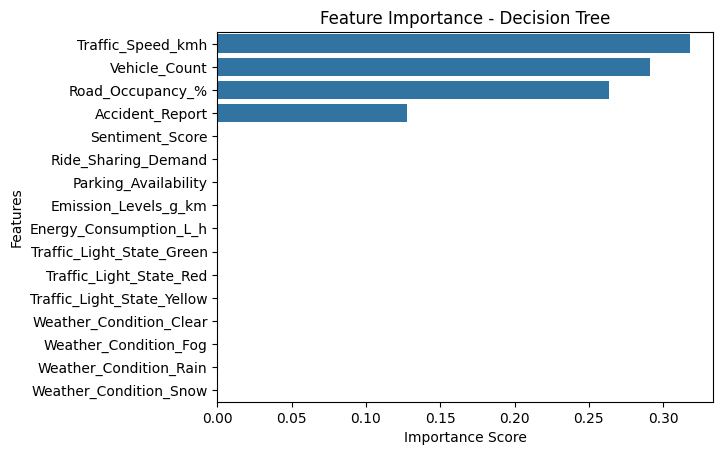

In [33]:
sns.barplot(x=feature_importance_df.values, y=feature_importance_df.index)

plt.title('Feature Importance - Decision Tree')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

En el árbol obtenido, la importancia se concentra en `Traffic_Speed_kmh`, `Vehicle_Count`, `Road_Occupancy_%` y `Accident_Report`, mientras que las demás variables no fueron utilizadas en las particiones. En este conjunto de datos particular, estas cuatro características son suficientes para reproducir prácticamente por completo la variable objetivo.

Esto ilustra la selección de variables **embebida** mencionada en la sección 7: por su propia estructura, el árbol deja de utilizar características que no aportan una reducción adicional de la impureza. No obstante, una importancia igual a cero en este árbol no demuestra, por sí sola, que una variable carezca de utilidad en cualquier otro modelo o conjunto de datos.


También podemos generar el árbol creado. Este modelo permite observar la lógica secuencial empleada para clasificar cada instancia, proporcionando una transparencia total sobre el proceso de inferencia. Para visualizar esta estructura jerárquica, se utiliza la función `plot_tree()`, la cual genera un diagrama de flujo que detalla cada nodo de decisión, los umbrales de corte y la distribución de clases en las hojas.


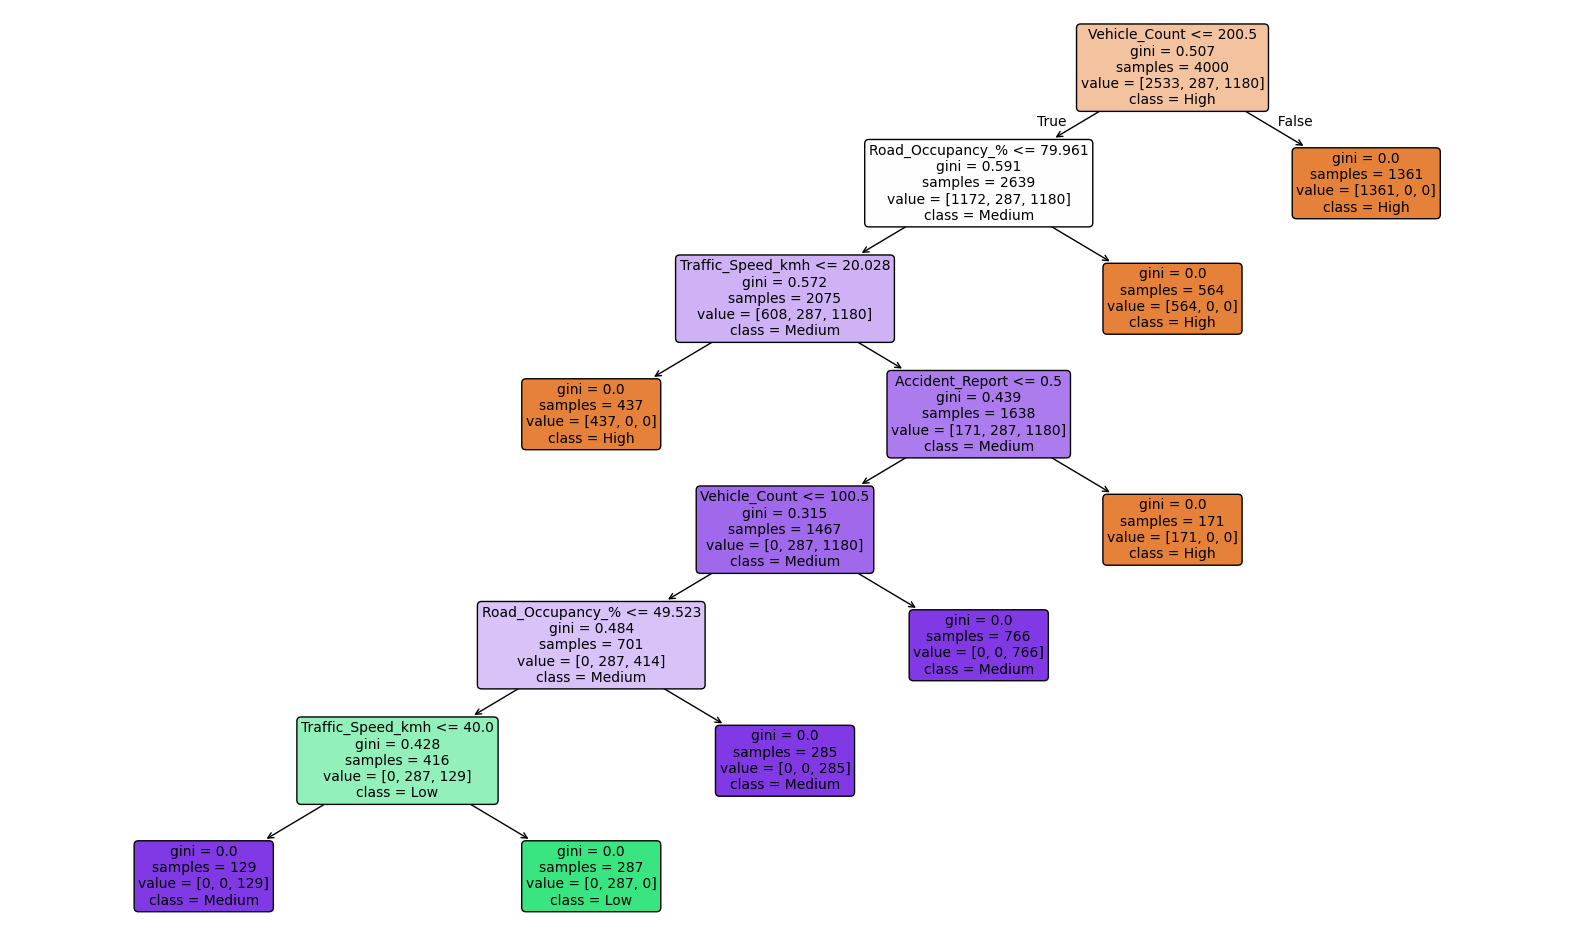

In [34]:
plt.figure(figsize=(20, 12))
plot_tree(
    best_decision_tree,
    feature_names=feature_names,
    class_names=best_decision_tree.classes_,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.show()


Al inspeccionar la arquitectura del árbol, cada nodo revela cinco métricas fundamentales que rigen la clasificación. En la parte superior encontramos el umbral de corte, donde el algoritmo evalúa si una característica cumple una condición específica (ej. $x_i < \theta$). La calidad de esta partición se mide a través del índice Gini. Complementariamente, el parámetro samples cuantifica el flujo de datos que alcanza el nodo, mientras que value desglosa la distribución de clases en ese punto. Finalmente, class designa la clase predominante que alcaza dicho nodo.  


A partir del atributo `value` es posible observar la distribución de clases entre las muestras que alcanzan una hoja. Para una instancia que llega a esa hoja, el árbol estima la probabilidad de pertenencia a cada clase mediante la frecuencia relativa de sus etiquetas:

$$
P(\text{clase}_k) = \frac{n_k}{n}
$$

donde $n_k$ es el número de muestras de la clase $k$ en la hoja y $n$ es el total de muestras que alcanzan esa hoja. La función `predict_proba()` devuelve estas proporciones para cada observación. Estas probabilidades permiten complementar la clase predicha, aunque no deben interpretarse automáticamente como probabilidades perfectamente calibradas.


Si se quiere mostrar el modelo de manera textual se puede utilizar `export_text`


In [35]:
arbol_reglas = export_text(best_decision_tree, feature_names=list(feature_names))
print(arbol_reglas)

|--- Vehicle_Count <= 200.50
|   |--- Road_Occupancy_% <= 79.96
|   |   |--- Traffic_Speed_kmh <= 20.03
|   |   |   |--- class: High
|   |   |--- Traffic_Speed_kmh >  20.03
|   |   |   |--- Accident_Report <= 0.50
|   |   |   |   |--- Vehicle_Count <= 100.50
|   |   |   |   |   |--- Road_Occupancy_% <= 49.52
|   |   |   |   |   |   |--- Traffic_Speed_kmh <= 40.00
|   |   |   |   |   |   |   |--- class: Medium
|   |   |   |   |   |   |--- Traffic_Speed_kmh >  40.00
|   |   |   |   |   |   |   |--- class: Low
|   |   |   |   |   |--- Road_Occupancy_% >  49.52
|   |   |   |   |   |   |--- class: Medium
|   |   |   |   |--- Vehicle_Count >  100.50
|   |   |   |   |   |--- class: Medium
|   |   |   |--- Accident_Report >  0.50
|   |   |   |   |--- class: High
|   |--- Road_Occupancy_% >  79.96
|   |   |--- class: High
|--- Vehicle_Count >  200.50
|   |--- class: High



### Análisis de resultados

El análisis de importancia muestra que el árbol concentra sus decisiones en `Traffic_Speed_kmh`, `Vehicle_Count`, `Road_Occupancy_%` y `Accident_Report`. Este resultado es coherente con la forma en que está construido el conjunto de datos: `Traffic_Condition` puede reproducirse mediante reglas basadas en estas cuatro variables. Por tanto, las importancias y los umbrales obtenidos son útiles para comprender el funcionamiento del árbol, pero no deberían interpretarse como evidencia de que estas variables sean, por sí solas, los principales determinantes de la congestión en un sistema de movilidad real.

Las reglas aprendidas muestran, dentro de este dataset, condiciones asociadas con los distintos niveles de `Traffic_Condition`. Por ejemplo, aparecen umbrales relacionados con un número elevado de vehículos, una ocupación alta de la vía, una velocidad promedio baja y la presencia de accidentes. Como la etiqueta fue construida a partir de estas variables, dichos umbrales deben entenderse principalmente como una recuperación de la lógica del conjunto de datos y no como reglas operativas que puedan trasladarse directamente a un sistema real de gestión del tráfico.

## 11. Persistencia del pipeline entrenado

Finalmente, se utiliza `joblib` para guardar el pipeline completo. De esta forma se conservan tanto las transformaciones de preprocesamiento como el árbol entrenado, y el modelo puede recibir posteriormente datos con la misma estructura original utilizada antes del preprocesamiento.

In [36]:
joblib.dump(best_model, 'decision_tree_pipeline.joblib')

['decision_tree_pipeline.joblib']

Utilizando `load()` se puede volver a cargar el pipeline completo:

In [37]:
loaded_model = joblib.load('decision_tree_pipeline.joblib')

## 12. Ejercicios

+ **Ejercicio 1**. Dado que solo cuatro variables presentan un valor de importancia distinto de $0$ para predecir el `Traffic_Condition`, explore la sensibilidad del modelo ante la pérdida de información. Para ello, seleccione una de las variables críticas y elimínela del proceso de entrenamiento. Posteriormente, reentrene el árbol de decisión optimizando sus hiperparámetros mediante `GridSearchCV`. Evalúe el desempeño utilizando el reporte de clasificación y la matriz de confusión, y compare la nueva jerarquía de importancia de las variables. ¿Cómo afecta la eliminación de un predictor clave a la estructura del árbol y a la precisión de las predicciones?


+ **Ejercicio 2**. Basándose en la estructura del mejor árbol obtenido, estime la probabilidad de clasificación de cada categoría basándose en la proporción de muestras en las hojas del árbol. Escriba su predicción de forma explícita. Posteriormente, verifique sus cálculos ejecutando `predict_proba()` en el conjunto de evaluación y analice la distribución de probabilidad generada por el modelo. ¿La distribución de probabilidad es la que esperaba?


+ **Ejercicio 3**. Entrene un árbol de decisión sin ninguna restricción estructural (`max_depth=None`, `max_leaf_nodes=None`) usando el mismo pipeline de preprocesamiento. Compare la exactitud en entrenamiento y en prueba frente al mejor modelo obtenido por `GridSearchCV`. ¿Qué evidencia concreta de sobreajuste observa? Use la celda de código de abajo para su experimento.


In [38]:
# Entrena aquí un árbol sin restricciones de profundidad (max_depth=None, max_leaf_nodes=None)
# y compara accuracy_score en train vs. test frente al mejor modelo obtenido por GridSearchCV.
